# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [1]:
# run this first if you dont have them installed in your env
%pip install pandas numpy matplotlib scipy


113.46s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Defaulting to user installation because normal site-packages is not writeable
  Using cached pandas-2.3.3-cp39-cp39-macosx_11_0_arm64.whl (10.8 MB)
  Using cached numpy-2.0.2-cp39-cp39-macosx_14_0_arm64.whl (5.3 MB)
  Using cached matplotlib-3.9.4-cp39-cp39-macosx_11_0_arm64.whl (7.8 MB)
  Using cached scipy-1.13.1-cp39-cp39-macosx_12_0_arm64.whl (30.3 MB)
  Using cached pytz-2026.6-py2.py3-none-any.whl (506 kB)
  Using cached pillow-11.3.0-cp39-cp39-macosx_11_0_arm64.whl (4.7 MB)
  Using cached kiwisolver-1.4.7-cp39-cp39-macosx_11_0_arm64.whl (64 kB)
  Using cached importlib_resources-6.5.2-py3-none-any.whl (37 kB)
  Using cached fonttools-4.60.2-cp39-cp39-macosx_10_9_universal2.whl (2.9 MB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached contourpy-1.3.0-cp39-cp39-macosx_11_0_arm64.whl (249 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrad

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("data/cars.csv")
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [11]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()


# Check for missing values
print(df.isna().sum())

# Check for duplicates
print(df.duplicated().sum())

# Look at the data
print(df.describe())

# Check common values
for col in df.columns:
    print(col)
    print(df[col].value_counts().head())


Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64
720
               Year    Engine HP  Engine Cylinders  Number of Doors  \
count  11914.000000  11845.00000      11884.000000     11908.000000   
mean    2010.384338    249.38607          5.628829         3.436093   
std        7.579740    109.19187          1.780559         0.881315   
min     1990.000000     55.00000          0.000000         2.000000   
25%     2007.000000    170.00000          4.000000         2.000000   
50%     2015.000000    227.00000          6.000000         4.000000   
75%     2016.000000    300.00000          6.000000         4.000000   
max     2017.000000   1001.00000         16.000000     

In [12]:
print(df["MSRP"].describe())
print(df["MSRP"].value_counts().head(10))
print(df["MSRP"].nlargest(10))

print(df[["city mpg", "highway MPG"]].describe())
print(df["Engine Cylinders"].value_counts(dropna=False))

count    1.191400e+04
mean     4.059474e+04
std      6.010910e+04
min      2.000000e+03
25%      2.100000e+04
50%      2.999500e+04
75%      4.223125e+04
max      2.065902e+06
Name: MSRP, dtype: float64
MSRP
2000     1036
29995      19
25995      19
20995      16
27995      16
23995      15
30995      15
21995      14
24995      14
26195      13
Name: count, dtype: int64
11362    2065902
11364    1705769
8486     1500000
11363    1500000
6351     1382750
6350     1380000
4024      643330
1622      548800
1626      548800
1629      535500
Name: MSRP, dtype: int64
           city mpg   highway MPG
count  11914.000000  11914.000000
mean      19.733255     26.637485
std        8.987798      8.863001
min        7.000000     12.000000
25%       16.000000     22.000000
50%       18.000000     26.000000
75%       22.000000     30.000000
max      137.000000    354.000000
Engine Cylinders
4.0     4752
6.0     4489
8.0     2031
12.0     230
5.0      225
10.0      68
0.0       56
NaN       30
3.0 

In [13]:
# Make a copy so the original data stays unchanged
clean = df.copy()

# Remove exact duplicate rows
clean = clean.drop_duplicates()

# Treat suspicious $2,000 prices as missing
# Keep the cars because their other information may be useful
clean.loc[clean["MSRP"] == 2000, "MSRP"] = np.nan

# Flag missing values without removing entire rows
clean["missing_engine_hp"] = clean["Engine HP"].isna()
clean["missing_cylinders"] = clean["Engine Cylinders"].isna()
clean["missing_fuel_type"] = clean["Engine Fuel Type"].isna()
clean["missing_doors"] = clean["Number of Doors"].isna()

print("Original rows:", len(df))
print("Cleaned rows:", len(clean))
print("Missing MSRP after cleaning:", clean["MSRP"].isna().sum())


Original rows: 11914
Cleaned rows: 11194
Missing MSRP after cleaning: 747


**Cleaning log:** fill in one row per problem.


**Cleaning log:** One row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | Duplicate rows | Used `df.duplicated().sum()` | 720 | Removed duplicates | To avoid counting the same records twice |
| 2 | Suspicious MSRP of $2,000 | Used `value_counts()` | 1,036 originally | Changed these prices to NaN | The price appeared unusually often and may be a placeholder |
| 3 | Missing Engine HP | Used `isna().sum()` | 69 originally | Flagged missing values | To keep useful vehicle data without guessing horsepower |
| 4 | Missing Engine Cylinders | Used `isna().sum()` | 30 originally | Flagged missing values | To avoid making up engine information |
| 5 | Missing Engine Fuel Type | Used `isna().sum()` | 3 originally | Flagged missing values | To preserve rows without guessing fuel types |



In [14]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean = df.copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names

In [15]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11914, 15)
engine_fuel_type     3
engine_hp           69
engine_cylinders    30
number_of_doors      6
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

['make', 'model', 'year', 'engine_fuel_type', 'engine_hp', 'engine_cylinders', 'transmission_type', 'driven_wheels', 'number_of_doors', 'vehicle_size', 'vehicle_style', 'highway_mpg', 'city_mpg', 'popularity', 'msrp']
Mean MSRP: $ 40594.74
Median MSRP: $ 29995.0


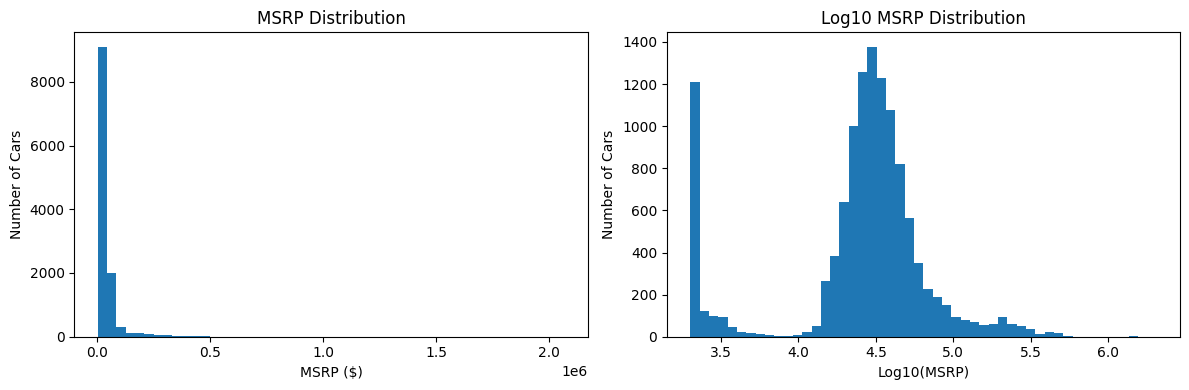

Percent above mean: 27.44 %


In [21]:
print(clean.columns.tolist())
# a) Mean and median MSRP

msrp = clean["msrp"].dropna()
mean_price = msrp.mean()
median_price = msrp.median()
print("Mean MSRP: $", round(mean_price, 2))
print("Median MSRP: $", round(median_price, 2))

# b) Two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(msrp, bins=50)
axes[0].set_title("MSRP Distribution")
axes[0].set_xlabel("MSRP ($)")
axes[0].set_ylabel("Number of Cars")

axes[1].hist(np.log10(msrp), bins=50)
axes[1].set_title("Log10 MSRP Distribution")
axes[1].set_xlabel("Log10(MSRP)")
axes[1].set_ylabel("Number of Cars")

plt.tight_layout()
plt.show()

# c) Percentage of cars above the mean
percent_above = (msrp > mean_price).mean() * 100
print("Percent above mean:", round(percent_above, 2), "%")


**Answer:**

**a)** The mean MSRP is $40,594.74, and the median is $29,995. The mean is higher because expensive luxury cars pull the average upward.

**b)** The original MSRP histogram is strongly right-skewed, with most cars at lower prices. The log10 histogram is more balanced, although it still shows a noticeable spike at very low prices.

**c)** 27.44% of cars cost more than the mean.

**d)** I would use the median of $29,995 on the homepage because it is less affected by extremely expensive cars and better represents a typical car.
  

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [24]:

# a) Mean and standard deviation by vehicle size for 2017
cars_2017 = clean[
    (clean["year"] == 2017) &
    (clean["highway_mpg"].between(5, 100))
]

stats_by_size = cars_2017.groupby("vehicle_size")["highway_mpg"].agg(["mean", "std"])

print("2017 Highway MPG by Vehicle Size:")
print(stats_by_size)

# b) Calculate z-scores for each car
civic_mean = stats_by_size.loc["Compact", "mean"]
civic_std = stats_by_size.loc["Compact", "std"]

volvo_mean = stats_by_size.loc["Large", "mean"]
volvo_std = stats_by_size.loc["Large", "std"]

civic_z = (42 - civic_mean) / civic_std
volvo_z = (34 - volvo_mean) / volvo_std

print("\nHonda Civic z-score:", round(civic_z, 2))
print("Volvo S90 z-score:", round(volvo_z, 2))


2017 Highway MPG by Vehicle Size:
                   mean       std
vehicle_size                     
Compact       30.979167  7.108374
Large         22.943158  3.502099
Midsize       29.507599  5.449709

Honda Civic z-score: 1.55
Volvo S90 z-score: 3.16


**Answer:**

**a)** For 2017 cars, compact cars have an average highway MPG of 30.98 with a standard deviation of 7.11. Large cars have an average of 22.94 MPG with a standard deviation of 3.50.

**b)** The Honda Civic has a z-score of 1.55, while the Volvo S90 has a z-score of 3.16.

**c)** The Volvo S90 is more fuel-efficient for its size class. The Honda Civic is 1.55 standard deviations above its class average, while the Volvo is 3.16 standard deviations above its class average. This makes the Volvo much more unusual and impressive for its size.

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

In [ ]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    # hint: rng.choice(values, size=len(values), replace=True)
    pass

# a, b)

# c)

**Answer:**

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

2017 Median MSRP: $ 36647.5
95% interval: [35870. 37625.]


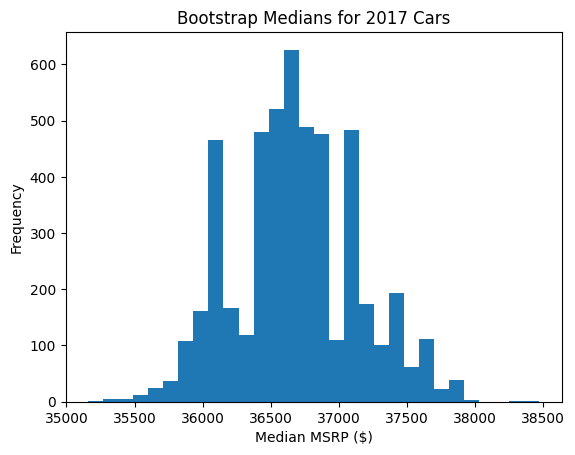

Selected make: Acura
Number of cars: 36
Small make 95% interval: [38170. 44950.]
All cars interval width: 1755.0
Small make interval width: 6780.0


In [26]:

def bootstrap_median(values, n_boot=5000):
    """Return an array of bootstrap medians."""
    medians = []

    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        medians.append(np.median(sample))

    return np.array(medians)


# a) Median MSRP for 2017 cars
cars_2017 = clean[clean["year"] == 2017]
prices_2017 = cars_2017["msrp"].dropna().to_numpy()

median_2017 = np.median(prices_2017)
print("2017 Median MSRP: $", round(median_2017, 2))


# b) Bootstrap 5000 times
boot_all = bootstrap_median(prices_2017)

ci_all = np.percentile(boot_all, [2.5, 97.5])
print("95% interval:", ci_all)

plt.hist(boot_all, bins=30)
plt.title("Bootstrap Medians for 2017 Cars")
plt.xlabel("Median MSRP ($)")
plt.ylabel("Frequency")
plt.show()


# c) Choose a make with fewer than 50 cars
make_counts = cars_2017.groupby("make")["msrp"].count()
small_make = make_counts[(make_counts > 0) & (make_counts < 50)].index[0]

small_prices = cars_2017[
    cars_2017["make"] == small_make
]["msrp"].dropna().to_numpy()

boot_small = bootstrap_median(small_prices)
ci_small = np.percentile(boot_small, [2.5, 97.5])

print("Selected make:", small_make)
print("Number of cars:", len(small_prices))
print("Small make 95% interval:", ci_small)
print("All cars interval width:", ci_all[1] - ci_all[0])
print("Small make interval width:", ci_small[1] - ci_small[0])


**Answer:**

**a)** The median MSRP for 2017 cars is $36,647.50.

**b)** After bootstrapping 5,000 times, the 95% confidence interval is $35,870 to $37,650. The histogram shows most of the bootstrap medians clustered around $36,000–$37,000.

**c)** I selected Acura, which has 36 cars in the 2017 dataset. Its 95% confidence interval is $38,235 to $44,950. This interval is wider than the interval for all 2017 cars because the smaller sample size creates more uncertainty in the median estimate.

**d)** Based on the 2017 car data, we estimate with 95% confidence that the market's median car price is between $35,870 and $37,650.

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [30]:

# a) Compare median MSRP by transmission type
cars = clean[clean["transmission_type"].isin(["AUTOMATIC", "MANUAL"])]

print("a) Median MSRP by transmission:")
print(cars.groupby("transmission_type")["msrp"].median())


# b) Compare year by transmission type
print("\nb) Year by transmission:")
print(cars.groupby("transmission_type")["year"].agg(["count", "mean", "median", "min", "max"]))


# c) Compare only 2015-2017 cars
recent = cars[cars["year"].between(2015, 2017)]

print("\nc) 2015-2017 Median MSRP:")
print(recent.groupby("transmission_type")["msrp"].median())

# Compare within each vehicle size
print("\nMedian MSRP by vehicle size:")
print(recent.groupby(
    ["vehicle_size", "transmission_type"]
)["msrp"].median().unstack())


# Mann-Whitney U test for compact cars
compact = recent[recent["vehicle_size"] == "Compact"]

auto = compact[compact["transmission_type"] == "AUTOMATIC"]["msrp"].dropna()
manual = compact[compact["transmission_type"] == "MANUAL"]["msrp"].dropna()

result = stats.mannwhitneyu(auto, manual, alternative="two-sided")

print("\nCompact automatic median:", auto.median())
print("Compact manual median:", manual.median())
print("Mann-Whitney U statistic:", result.statistic)
print("p-value:", result.pvalue)


a) Median MSRP by transmission:
transmission_type
AUTOMATIC    32565.0
MANUAL       18720.0
Name: msrp, dtype: float64

b) Year by transmission:
                   count         mean  median   min   max
transmission_type                                        
AUTOMATIC           8266  2011.717276  2015.0  1990  2017
MANUAL              2935  2005.760136  2008.0  1990  2017

c) 2015-2017 Median MSRP:
transmission_type
AUTOMATIC    36732.5
MANUAL       27090.0
Name: msrp, dtype: float64

Median MSRP by vehicle size:
transmission_type  AUTOMATIC   MANUAL
vehicle_size                         
Compact              25990.0  26255.0
Large                44540.0  38395.0
Midsize              37605.0  26920.0

Compact automatic median: 25990.0
Compact manual median: 26255.0
Mann-Whitney U statistic: 346203.0
p-value: 0.0941621665794619


**Answer:**

**a)** The median MSRP for automatic cars is $32,565, while manual cars have a median of $18,720. Overall, manual cars appear cheaper.

**b)** Manual cars tend to be older. Their median model year is 2008, compared to 2015 for automatic cars. This could explain part of the price difference.

**c)** For 2015–2017 cars, the median price is $36,732.50 for automatics and $27,090 for manuals. However, when comparing vehicle sizes, the results vary. Compact manuals are slightly more expensive ($26,255 vs. $25,990), while large and midsize manuals are cheaper. For compact cars, the Mann–Whitney U test gives a p-value of 0.094, which is above 0.05. This means there is not enough evidence of a statistically significant difference in compact car prices.

**d)** Manual cars may be cheaper overall, but age and vehicle size affect the comparison, so we shouldn't assume manuals are always the better budget option.

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [32]:

# a) Welch t-test: 4-door vs 2-door
# Use valid highway MPG values
cars = clean[
    (clean["highway_mpg"] > 0) &
    (clean["number_of_doors"].isin([2, 4]))
]

four = cars[cars["number_of_doors"] == 4]["highway_mpg"].dropna()
two = cars[cars["number_of_doors"] == 2]["highway_mpg"].dropna()

mean_four = four.mean()
mean_two = two.mean()
difference = mean_four - mean_two

test = stats.ttest_ind(four, two, equal_var=False)

print("a) Welch t-test")
print("4-door average MPG:", round(mean_four, 2))
print("2-door average MPG:", round(mean_two, 2))
print("Difference in means:", round(difference, 2))
print("p-value:", test.pvalue)


# b) Yearly gas savings
miles = 12000
gas_price = 3.50

cost_four = miles * gas_price / mean_four
cost_two = miles * gas_price / mean_two
savings = cost_two - cost_four

print("\nb) Yearly gas savings")
print("4-door yearly cost: $", round(cost_four, 2))
print("2-door yearly cost: $", round(cost_two, 2))
print("4-door yearly savings: $", round(savings, 2))


# c) Simulation: 30 cars per group, 1000 times
n_sims = 1000
hits = 0

for _ in range(n_sims):
    sample_four = rng.choice(four.to_numpy(), 30, replace=False)
    sample_two = rng.choice(two.to_numpy(), 30, replace=False)

    result = stats.ttest_ind(
        sample_four, sample_two, equal_var=False
    )

    if result.pvalue < 0.05:
        hits += 1

fraction = hits / n_sims

print("\nc) Simulation results")
print("Significant tests:", hits, "out of", n_sims)
print("Fraction significant:", round(fraction, 3))
print("Percentage significant:", round(fraction * 100, 2), "%")


a) Welch t-test
4-door average MPG: 27.43
2-door average MPG: 25.35
Difference in means: 2.08
p-value: 3.08668000886458e-41

b) Yearly gas savings
4-door yearly cost: $ 1531.08
2-door yearly cost: $ 1656.56
4-door yearly savings: $ 125.48

c) Simulation results
Significant tests: 158 out of 1000
Fraction significant: 0.158
Percentage significant: 15.8 %


**Answer:**
**a)** The average highway MPG for 4-door cars is 27.43, compared to 25.35 for 2-door cars. The difference is 2.08 MPG. The p-value is approximately 3.09 × 10⁻⁴¹, which is statistically significant.

**b)** Assuming 12,000 miles per year and $3.50 per gallon, the average 4-door driver would save approximately $125.48 per year on gas.

**c)** Out of 1,000 simulations using 30 cars per group, 141 tests were statistically significant. This means only 14.1% of the smaller-sample tests detected a significant difference.

**d)** I would not advertise 4-door cars as significantly more fuel-efficient because the difference is relatively small. Instead, I would say that 4-door cars in this dataset average about 2 MPG more on the highway, which could save drivers around $125 per year in gas.

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:**
Based on the data, manual cars generally cost less than automatic cars, with a median price of $18,720 compared to $32,565 for automatics. However, manual cars in the dataset also tend to be older, which may explain part of the price difference. When comparing newer compact cars from 2015–2017, manual cars actually had a slightly higher median price of $26,255 compared to $25,990 for automatics. Another important finding is that the overall median car price is $29,995, which better represents a typical car price than the average of $40,594.74. One limitation is that the dataset includes cars from different years and vehicle sizes, so price comparisons may not always be fair without accounting for those differences.

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [ ]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [ ]:
# S2